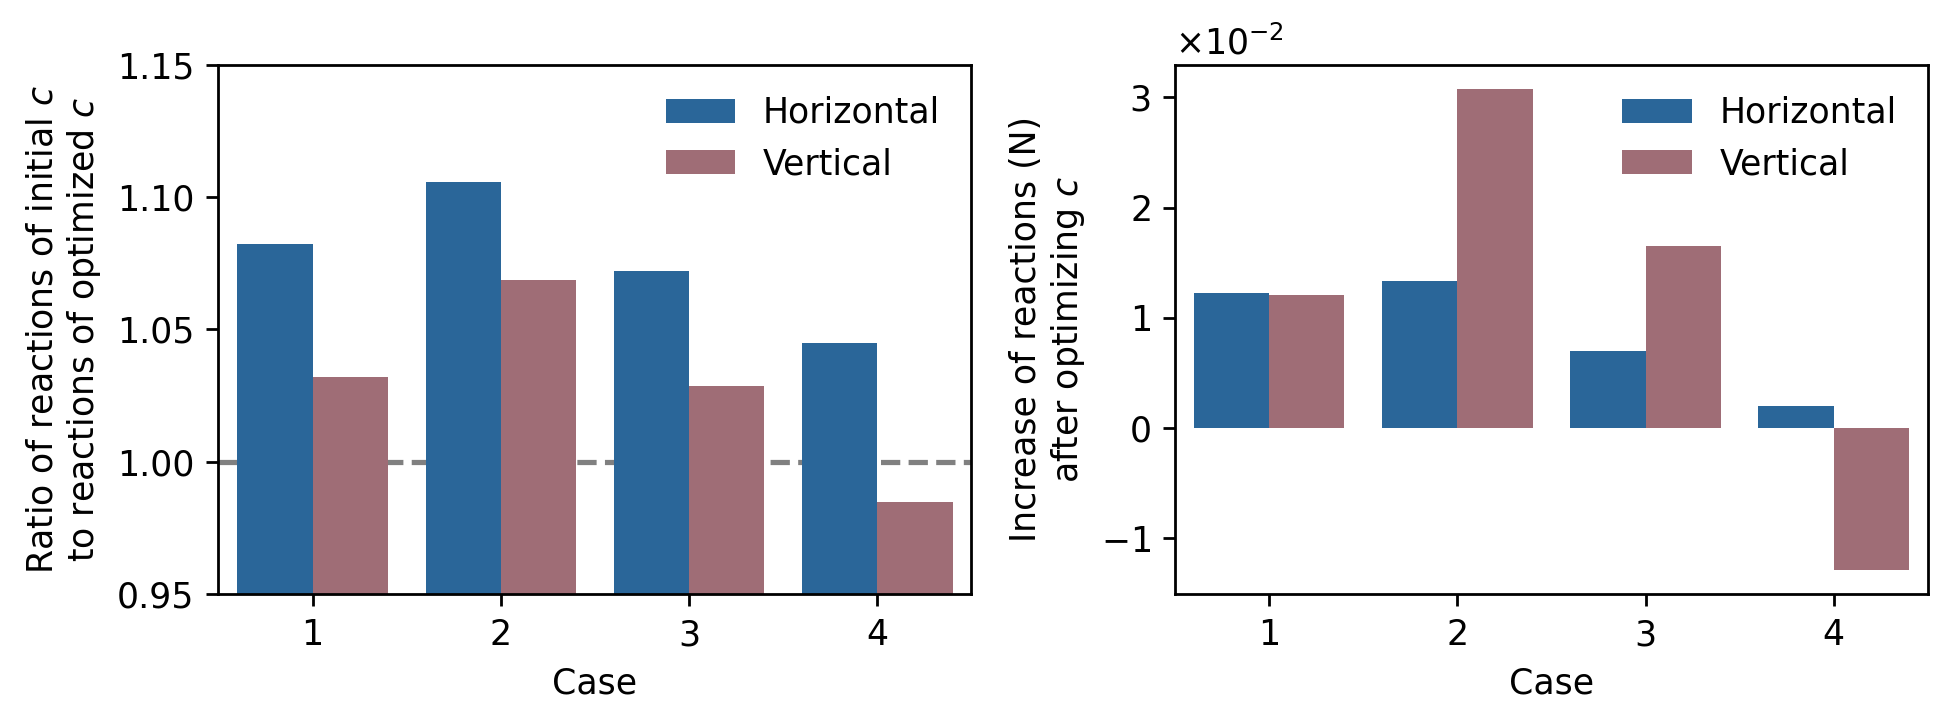

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

thres_paths = {
    4: "../../outputs/semisphere-2025-11-13-16-04-30-Case4-thres3000-smooth400/records_opt.csv",
    3: "../../outputs/semisphere-2025-11-13-16-04-26-Case3-thres3000-smooth400/records_opt.csv",
    2: "../../outputs/semisphere-2025-11-13-16-04-20-Case2-thres3000-smooth400/records_opt.csv",
    1: "../../outputs/semisphere-2025-11-13-16-04-12-Case1-thres3000-smooth400/records_opt.csv",
}

dfs = {
    key: pd.read_csv(val) for key, val in thres_paths.items()
}

dfs_processed = {
    key: pd.DataFrame({"thres": [key, key], "type": ["Horizontal", "Vertical"], "value": [val["bottom_x"].values[-1]/val["bottom_x"].values[0], val["bottom_y"].values[-1]/val["bottom_y"].values[0]], "abs_increase": [val["bottom_x"].values[-1]-val["bottom_x"].values[0], val["bottom_y"].values[-1]-val["bottom_y"].values[0]]}) for key, val in dfs.items()
}

df_thres = pd.concat(dfs_processed.values())

no_thres_paths = {
    4: "../../outputs/semisphere-2025-11-07-16-05-30-Case4/records_opt.csv",
    3: "../../outputs/semisphere-2025-11-07-15-57-56-Case3/records_opt.csv",
    2: "../../outputs/semisphere-2025-11-07-15-58-10-Case2/records_opt.csv",
    1: "../../outputs/semisphere-2025-11-07-14-19-12-Case1/records_opt.csv",
}

dfs = {
    key: pd.read_csv(val) for key, val in no_thres_paths.items()
}

dfs_processed = {
    key: pd.DataFrame({"thres": [key, key], "type": ["Horizontal", "Vertical"], "value": [val["bottom_x"].values[-1]/val["bottom_x"].values[0], val["bottom_y"].values[-1]/val["bottom_y"].values[0]], "abs_increase": [val["bottom_x"].values[-1]-val["bottom_x"].values[0], val["bottom_y"].values[-1]-val["bottom_y"].values[0]]}) for key, val in dfs.items()
}

df_no_thres = pd.concat(dfs_processed.values())

# df_thres["with_grad_penalty"] = "Yes"
# df_no_thres["with_grad_penalty"] = "No"

import seaborn as sns

plt.figure(figsize=(8,3.0), dpi=250)
ax = plt.subplot(121)
sns.barplot(data=df_thres, x="thres", y="value", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
xlim = ax.get_xlim()
ax.hlines(1.0, *ax.get_xlim(), ls="--", colors="grey", zorder=0)
ax.set_xlim(xlim)
ax.set_ylim([0.95, 1.15])
# ax.set_yticks([0.95, 1.0, 1.05, 1.1])
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False)
ax.set_xlabel(r"Case")
ax.set_ylabel("Ratio of reactions of initial $c$\nto reactions of optimized $c$")

ax = plt.subplot(122)
sns.barplot(data=df_thres, x="thres", y="abs_increase", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False)
ax.set_xlabel(r"Case")
ax.set_ylabel("Increase of reactions (N)\nafter optimizing $c$")
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
# ax.set_ylim([0, 2e-3])

plt.tight_layout()
plt.savefig("semisphere_reaction_diff.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [15]:
df_thres

,thres,type,value,abs_increase
0,4,Horizontal,1.043113,0.001891
1,4,Vertical,0.996512,-0.002895
0,3,Horizontal,1.039420,0.003857
1,3,Vertical,1.004175,0.002424
0,2,Horizontal,1.059994,0.007592
1,2,Vertical,1.033343,0.014978
0,1,Horizontal,1.029644,0.004408
1,1,Vertical,0.990366,-0.003661


In [16]:
df_no_thres

,thres,type,value,abs_increase
0,4,Horizontal,1.042656,0.001871
1,4,Vertical,0.959242,-0.033829
0,3,Horizontal,1.120444,0.011783
1,3,Vertical,1.062543,0.036320
0,2,Horizontal,1.149763,0.018952
1,2,Vertical,1.101982,0.045812
0,1,Horizontal,1.121942,0.018133
1,1,Vertical,1.059127,0.022472


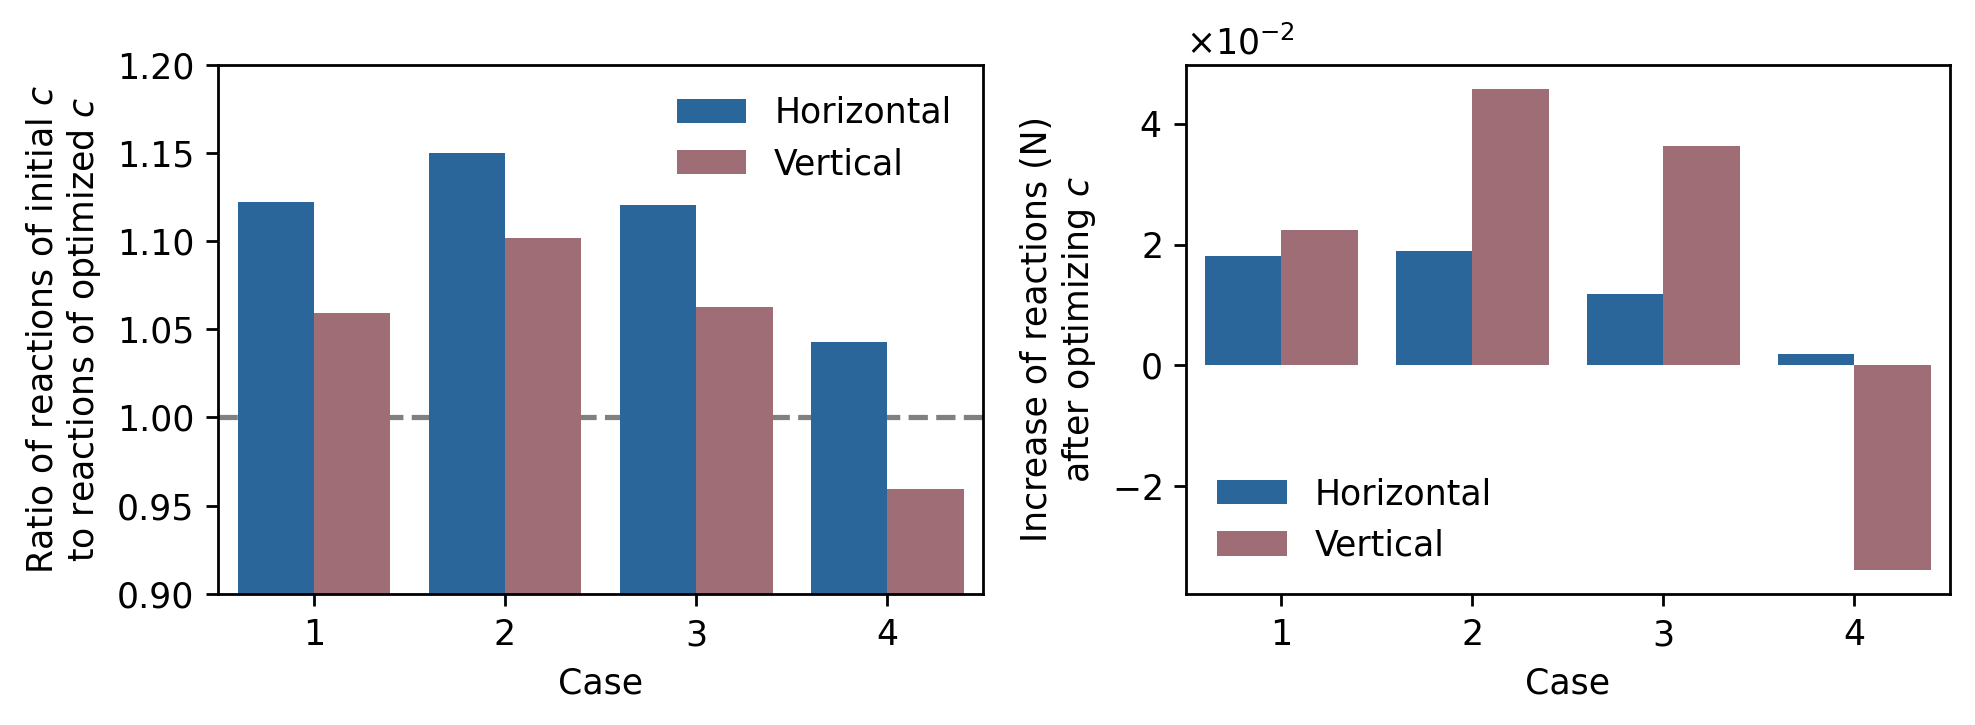

In [31]:
import seaborn as sns

plt.figure(figsize=(8,3.0), dpi=250)
ax = plt.subplot(121)
sns.barplot(data=df_no_thres, x="thres", y="value", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
xlim = ax.get_xlim()
ax.hlines(1.0, *ax.get_xlim(), ls="--", colors="grey", zorder=0)
ax.set_xlim(xlim)
ax.set_ylim([0.9, 1.2])
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False)
ax.set_xlabel(r"Case")
ax.set_ylabel("Ratio of reactions of initial $c$\nto reactions of optimized $c$")

ax = plt.subplot(122)
sns.barplot(data=df_no_thres, x="thres", y="abs_increase", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False)
ax.set_xlabel(r"Case")
ax.set_ylabel("Increase of reactions (N)\nafter optimizing $c$")
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
# ax.set_ylim([0, 2e-3])

plt.tight_layout()
plt.savefig("semisphere_reaction_diff_no_penalty.pdf", bbox_inches="tight")
plt.show()
plt.close()